# CartPole-v1 with policy gradient: Part 1 (no baseline) and Part 2 (baseline)

**The game.** A pole stands on a cart. Each step you push the cart left or right. You get +1 for every step the pole stays up. The episode ends when the pole tips more than 12° or the cart leaves the track, or after 500 steps (the maximum score).

**The method** is the same one running in your Pong notebook: play some episodes, then nudge a small neural network so that moves followed by good outcomes become more likely.

**How to run (Colab):** Runtime → Run all. The whole notebook takes roughly 5–15 minutes on a normal CPU runtime (no GPU needed). It trains **3 seeds × 2 settings** (no baseline / mean baseline). A *seed* fixes the random numbers, so different seeds are independent repeats of the same experiment. Repeating matters here: one lucky or unlucky run can't tell you whether the baseline helps.

**Outputs** (saved to Google Drive in `MyDrive/rl_hw1_cartpole/`, or to a local folder outside Colab):
- training curves with the 100-episode moving average, for each setting (required plot)
- 500-episode evaluation histograms with mean and standard deviation (required plot)
- a comparison of all seeds, and a direct measurement of gradient noise with and without the baseline (evidence for Part 2)

In [ ]:
!pip install -q "gymnasium>=1.0"

In [ ]:
import os, json, time, copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import gymnasium as gym

print(f"gymnasium {gym.__version__} | torch {torch.__version__}")
torch.set_num_threads(1)                                        # tiny network: one thread is fastest
torch.distributions.Distribution.set_default_validate_args(False)   # skip slow input checks

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110})

try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/rl_hw1_cartpole"
except ImportError:
    OUT = "./rl_hw1_cartpole"
os.makedirs(OUT, exist_ok=True)
print("Results folder:", OUT)

gymnasium 1.4.0 | torch 2.11.0+cpu
Mounted at /content/drive
Results folder: /content/drive/MyDrive/rl_hw1_cartpole


## Settings

| Setting | Value | Meaning |
|---|---|---|
| `GAMMA` | 0.95 | discount factor required by the assignment |
| `LR` | 0.01 | Adam learning rate, as the assignment suggests |
| `BATCH_EPISODES` | 5 | episodes played before each learning step |
| `N_EPISODES` | 1500 | training episodes per run |
| `TIME_LIMIT_FIX` | True | how to treat the 500-step cut-off (explained in the edge-case section) |
| `SEEDS` | 0, 1, 2 | independent repeats |

In [ ]:
GAMMA = 0.95
LR = 0.01
HIDDEN = 128
BATCH_EPISODES = 5
N_EPISODES = 1500
TIME_LIMIT_FIX = True
SEEDS = [0, 1, 2]
BASELINES = ["none", "mean"]        # "none" = Part 1, "mean" = Part 2
EVAL_EPISODES = 500
MAX_STEPS = 500                     # CartPole-v1 cuts every episode at 500 steps

## Check 1: what does random play score?
A player that pushes left or right at random should keep the pole up for only about 20 steps. That's the "before learning" reference.

In [ ]:
env = gym.make("CartPole-v1")
print("State:", env.observation_space, "\n -> [cart position, cart speed, pole angle, pole angular speed]")
print("Actions:", env.action_space, "-> 0 = push left, 1 = push right")
rng = np.random.default_rng(0)
random_scores = []
for ep in range(200):
    env.reset(seed=10_000 + ep)
    total, done = 0, False
    while not done:
        _, r, term, trunc, _ = env.step(int(rng.integers(2)))
        total += r; done = term or trunc
    random_scores.append(total)
env.close()
print(f"Random play over 200 episodes: mean {np.mean(random_scores):.1f}, std {np.std(random_scores):.1f}")

State: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32) 
 -> [cart position, cart speed, pole angle, pole angular speed]
Actions: Discrete(2) -> 0 = push left, 1 = push right
Random play over 200 episodes: mean 21.6, std 10.8


## The policy network
4 numbers in (the state), one hidden layer of 128 units, 2 scores out (left, right), turned into probabilities. The agent **samples** its move from those probabilities, which is how it explores.

In [ ]:
class PolicyNet(nn.Module):
    def __init__(self, hidden=HIDDEN):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(4, hidden), nn.ReLU(), nn.Linear(hidden, 2))

    def forward(self, x):
        return self.net(x)


def discounted_returns(rewards, gamma, truncated=False):
    """G_t = r_t + gamma r_{t+1} + ... computed backward. If the episode was cut by the time limit
    (not a real failure) and TIME_LIMIT_FIX is on, add the value of 'keep balancing', 1/(1-gamma),
    discounted from the cut-off point."""
    G = np.zeros(len(rewards), dtype=np.float32)
    running = (1.0 / (1.0 - gamma)) if (truncated and TIME_LIMIT_FIX) else 0.0
    for t in reversed(range(len(rewards))):
        running = rewards[t] + gamma * running
        G[t] = running
    return G


print(discounted_returns([0, 0, 1], 0.5), "expected [0.25, 0.5, 1.0]")
print(discounted_returns([1, 1, 1], 0.95), "expected [2.8525, 1.95, 1.0]")

[0.25 0.5  1.  ] expected [0.25, 0.5, 1.0]
[2.8525 1.95   1.    ] expected [2.8525, 1.95, 1.0]


## Playing one episode, and the learning step

`play_episode` records (state, action, reward) until the pole falls or the 500-step limit hits, and remembers **which** of the two happened.

`pg_update` is the policy gradient. For every move: **log-probability of the move × weight**, summed, and the network is nudged to make that sum larger.
- `"none"` (Part 1): weight = Gₜ. In CartPole every reward is +1, so **every** Gₜ is positive: every move gets pushed up, just some more than others. That's why it's noisy.
- `"mean"` (Part 2): weight = (Gₜ − average G in the batch) ÷ spread of G. Moves that did better than average go up, worse than average go down.

In [ ]:
def play_episode(env, policy, seed=None, greedy=False):
    s, _ = env.reset(seed=seed)
    states, actions, rewards = [], [], []
    while True:
        with torch.no_grad():
            logits = policy(torch.as_tensor(s, dtype=torch.float32))
        a = int(logits.argmax()) if greedy else int(torch.distributions.Categorical(logits=logits).sample())
        states.append(s); actions.append(a)
        s, r, terminated, truncated, _ = env.step(a)
        rewards.append(float(r))
        if terminated or truncated:
            return np.array(states, dtype=np.float32), np.array(actions), np.array(rewards, dtype=np.float32), bool(truncated and not terminated)


def episode_weights(episodes, baseline, mean_only=False):
    G = np.concatenate([discounted_returns(e[2], GAMMA, e[3]) for e in episodes])
    if baseline == "none":
        return G
    if mean_only:
        return G - G.mean()
    return (G - G.mean()) / (G.std() + 1e-8)


def policy_loss(policy, episodes, weights):
    X = torch.as_tensor(np.concatenate([e[0] for e in episodes]))
    A = torch.as_tensor(np.concatenate([e[1] for e in episodes]))
    logp = torch.distributions.Categorical(logits=policy(X)).log_prob(A)
    return -(logp * torch.as_tensor(weights)).sum() / len(episodes)

## Train every (setting, seed) pair
Progress prints every 100 episodes. Each run's reward history and final network are saved.

Policy gradient can **collapse**: a run reaches 500 and then one bad update knocks it back down. So we also keep a copy of the network from the moment its 100-episode average was highest ("best checkpoint"). The required evaluation uses the **final** network, as the assignment asks; the best checkpoint is evaluated as an extra, which makes collapses visible in the report.

In [ ]:
def train(baseline, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    env = gym.make("CartPole-v1")
    policy = PolicyNet()
    opt = torch.optim.Adam(policy.parameters(), lr=LR)
    rewards, ep_seed = [], seed * 100_000
    best_ma, best_state = -1.0, None
    t0 = time.time()
    while len(rewards) < N_EPISODES:
        eps = []
        for _ in range(BATCH_EPISODES):
            eps.append(play_episode(env, policy, seed=ep_seed)); ep_seed += 1
        loss = policy_loss(policy, eps, episode_weights(eps, baseline))
        opt.zero_grad(); loss.backward(); opt.step()
        rewards += [float(e[2].sum()) for e in eps]
        if len(rewards) >= 100 and np.mean(rewards[-100:]) > best_ma:
            best_ma, best_state = np.mean(rewards[-100:]), copy.deepcopy(policy.state_dict())
        if len(rewards) % 100 < BATCH_EPISODES:
            print(f"  [{baseline}, seed {seed}] episode {len(rewards):5d} | last-100 avg {np.mean(rewards[-100:]):6.1f} | {time.time() - t0:5.0f}s")
    env.close()
    torch.save(policy.state_dict(), os.path.join(OUT, f"policy_{baseline}_seed{seed}.pt"))
    torch.save(best_state, os.path.join(OUT, f"policy_best_{baseline}_seed{seed}.pt"))
    with open(os.path.join(OUT, f"rewards_{baseline}_seed{seed}.json"), "w") as f:
        json.dump(rewards, f)
    return {"rewards": rewards, "policy": policy, "best_state": best_state, "best_ma": best_ma}


results = {}
for baseline in BASELINES:
    for seed in SEEDS:
        print(f"Training baseline = {baseline}, seed = {seed}")
        results[(baseline, seed)] = train(baseline, seed)

Training baseline = none, seed = 0
  [none, seed 0] episode   100 | last-100 avg   36.6 |     1s
  [none, seed 0] episode   200 | last-100 avg  109.6 |     5s
  [none, seed 0] episode   300 | last-100 avg  164.2 |    10s
  [none, seed 0] episode   400 | last-100 avg  158.5 |    14s
  [none, seed 0] episode   500 | last-100 avg  195.4 |    20s
  [none, seed 0] episode   600 | last-100 avg  188.1 |    26s
  [none, seed 0] episode   700 | last-100 avg   82.0 |    28s
  [none, seed 0] episode   800 | last-100 avg  235.9 |    35s
  [none, seed 0] episode   900 | last-100 avg  173.5 |    41s
  [none, seed 0] episode  1000 | last-100 avg  129.5 |    44s
  [none, seed 0] episode  1100 | last-100 avg  155.1 |    50s
  [none, seed 0] episode  1200 | last-100 avg  172.5 |    54s
  [none, seed 0] episode  1300 | last-100 avg  220.1 |    61s
  [none, seed 0] episode  1400 | last-100 avg  204.4 |    67s
  [none, seed 0] episode  1500 | last-100 avg  401.1 |    79s
Training baseline = none, seed = 1


## Required plot: training curves
One figure per setting (seed 0), episode reward plus the 100-episode moving average. For the first 99 episodes the average uses however many episodes exist so far.

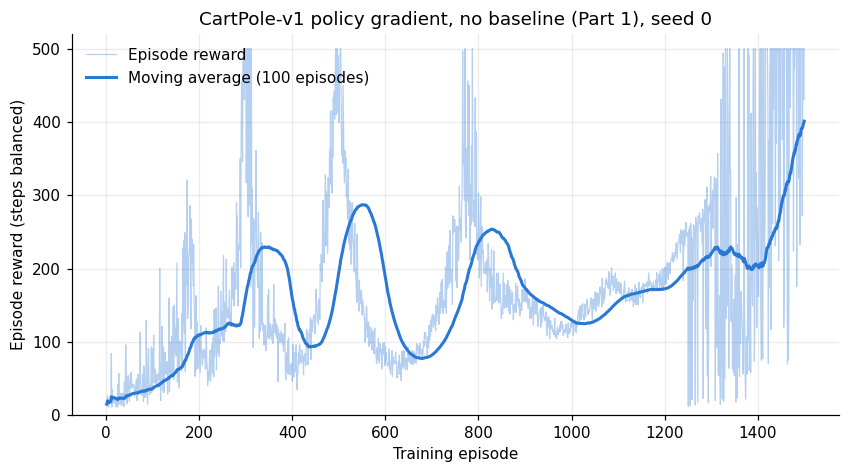

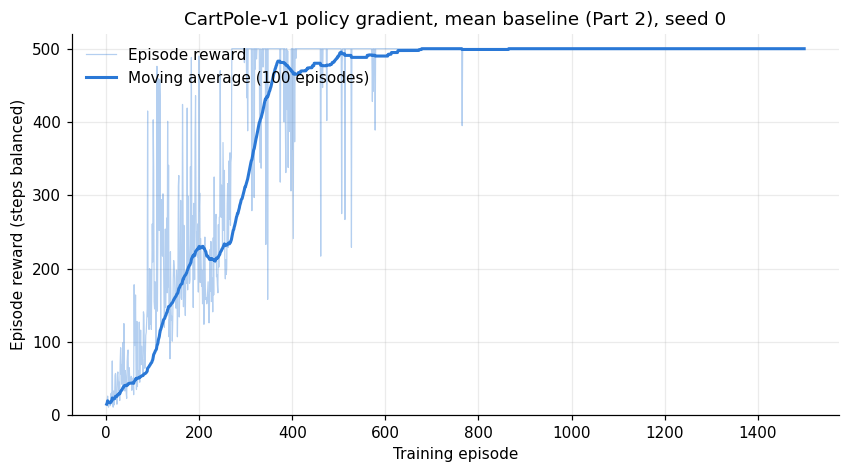

In [ ]:
def moving_average(x, w=100):
    x = np.asarray(x, dtype=float)
    c = np.concatenate([[0.0], np.cumsum(x)])
    i = np.arange(len(x)); lo = np.maximum(0, i - w + 1)
    return (c[i + 1] - c[lo]) / (i + 1 - lo)


names = {"none": "no baseline (Part 1)", "mean": "mean baseline (Part 2)"}
for baseline in BASELINES:
    r = results[(baseline, 0)]["rewards"]
    ep = np.arange(1, len(r) + 1)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(ep, r, color=BLUE, lw=0.8, alpha=0.35, label="Episode reward")
    ax.plot(ep, moving_average(r), color=BLUE, lw=2, label="Moving average (100 episodes)")
    ax.set_xlabel("Training episode"); ax.set_ylabel("Episode reward (steps balanced)")
    ax.set_ylim(0, 520)
    ax.set_title(f"CartPole-v1 policy gradient, {names[baseline]}, seed 0")
    ax.legend(loc="upper left", frameon=False)
    fig.savefig(os.path.join(OUT, f"training_{baseline}_seed0.png"), dpi=150, bbox_inches="tight")
    plt.show()

## Part 2 evidence: all seeds side by side
Thin lines are individual seeds' moving averages; the thick line is their mean.

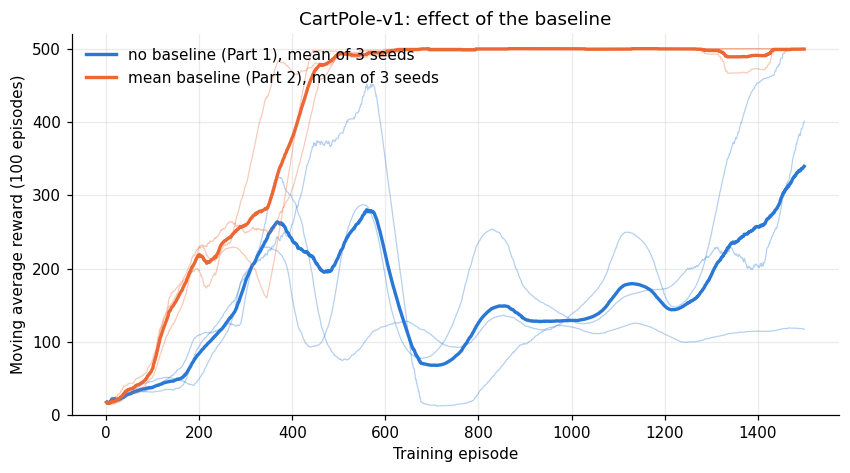

setting | seed | last-100 avg | best 100-avg | first episode where the 100-avg reached 475
none    |    0 |        401.1 |        401.1 | None
none    |    1 |        500.0 |        500.0 | 1443
none    |    2 |        117.4 |        451.6 | None
mean    |    0 |        500.0 |        500.0 | 365
mean    |    1 |        498.5 |        500.0 | 483
mean    |    2 |        500.0 |        500.0 | 433


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for baseline, color in [("none", BLUE), ("mean", ORANGE)]:
    mas = np.array([moving_average(results[(baseline, s)]["rewards"]) for s in SEEDS])
    ep = np.arange(1, mas.shape[1] + 1)
    for m in mas:
        ax.plot(ep, m, color=color, lw=0.8, alpha=0.35)
    ax.plot(ep, mas.mean(0), color=color, lw=2.2, label=f"{names[baseline]}, mean of {len(SEEDS)} seeds")
ax.set_xlabel("Training episode"); ax.set_ylabel("Moving average reward (100 episodes)")
ax.set_ylim(0, 520)
ax.set_title("CartPole-v1: effect of the baseline")
ax.legend(loc="upper left", frameon=False)
fig.savefig(os.path.join(OUT, "baseline_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

print("setting | seed | last-100 avg | best 100-avg | first episode where the 100-avg reached 475")
for baseline in BASELINES:
    for s in SEEDS:
        r = results[(baseline, s)]["rewards"]; ma = moving_average(r)
        hit = next((i + 1 for i in range(99, len(ma)) if ma[i] >= 475), None)
        print(f"{baseline:7s} | {s:4d} | {np.mean(r[-100:]):12.1f} | {results[(baseline, s)]['best_ma']:12.1f} | {hit}")

## Required plot: 500 evaluation episodes with the trained model
The agent keeps **sampling** its moves (as during training). Evaluation episodes use seeds that training never used. The histogram and the mean ± std are for seed 0's model; the table covers every seed.

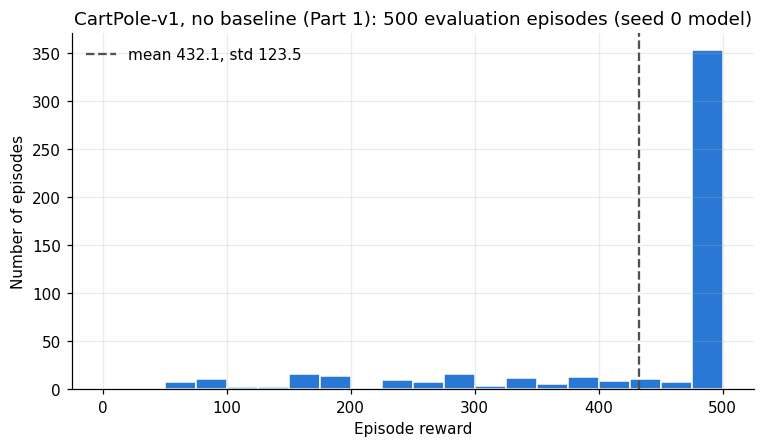

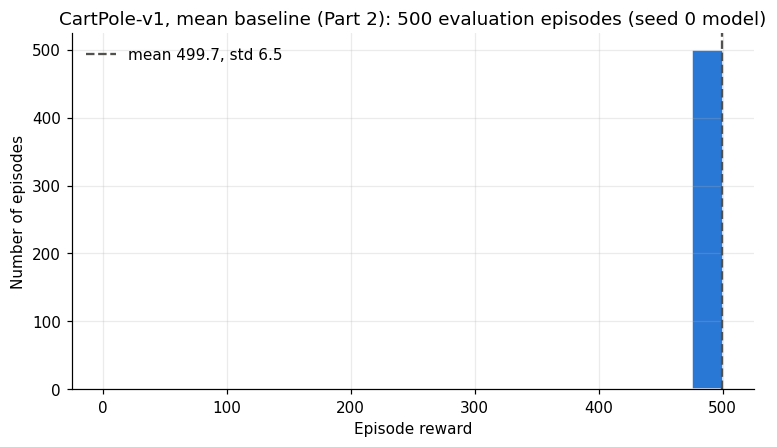

setting | seed | FINAL model: mean ± std (share at 500) | BEST checkpoint: mean ± std (share at 500)
none    |    0 |  432.1 ± 123.5 (0.69)          |  437.4 ± 119.0 (0.69)
none    |    1 |  500.0 ±   0.0 (1.00)          |  500.0 ±   0.0 (1.00)
none    |    2 |   99.0 ±  15.0 (0.00)          |  391.7 ± 190.0 (0.74)
mean    |    0 |  499.7 ±   6.5 (1.00)          |  499.9 ±   1.4 (1.00)
mean    |    1 |  500.0 ±   0.0 (1.00)          |  499.7 ±   5.9 (1.00)
mean    |    2 |  500.0 ±   0.0 (1.00)          |  499.6 ±   6.7 (1.00)


In [ ]:
def evaluate(policy, n=EVAL_EPISODES, greedy=False, seed_offset=900_000):
    env = gym.make("CartPole-v1")
    scores = [float(play_episode(env, policy, seed=seed_offset + i, greedy=greedy)[2].sum()) for i in range(n)]
    env.close()
    return np.array(scores)


eval_scores, eval_best = {}, {}
for baseline in BASELINES:
    for s in SEEDS:
        eval_scores[(baseline, s)] = evaluate(results[(baseline, s)]["policy"])
        best_net = PolicyNet(); best_net.load_state_dict(results[(baseline, s)]["best_state"])
        eval_best[(baseline, s)] = evaluate(best_net)

for baseline in BASELINES:
    sc = eval_scores[(baseline, 0)]
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.hist(sc, bins=np.arange(0, 525, 25), color=BLUE, edgecolor="white", linewidth=1)
    ax.axvline(sc.mean(), color=GRAY, ls="--", lw=1.5, label=f"mean {sc.mean():.1f}, std {sc.std():.1f}")
    ax.set_xlabel("Episode reward"); ax.set_ylabel("Number of episodes")
    ax.set_title(f"CartPole-v1, {names[baseline]}: 500 evaluation episodes (seed 0 model)")
    ax.legend(frameon=False)
    fig.savefig(os.path.join(OUT, f"eval_hist_{baseline}_seed0.png"), dpi=150, bbox_inches="tight")
    plt.show()

print("setting | seed | FINAL model: mean ± std (share at 500) | BEST checkpoint: mean ± std (share at 500)")
for baseline in BASELINES:
    for s in SEEDS:
        f_, b_ = eval_scores[(baseline, s)], eval_best[(baseline, s)]
        print(f"{baseline:7s} | {s:4d} | {f_.mean():6.1f} ± {f_.std():5.1f} ({np.mean(f_ == 500):.2f})          "
              f"| {b_.mean():6.1f} ± {b_.std():5.1f} ({np.mean(b_ == 500):.2f})")
with open(os.path.join(OUT, "eval_scores.json"), "w") as f:
    json.dump({"final": {f"{b}_seed{s}": v.tolist() for (b, s), v in eval_scores.items()},
               "best": {f"{b}_seed{s}": v.tolist() for (b, s), v in eval_best.items()}}, f)

## Test: does the baseline really reduce gradient noise?

This measures the claim behind Part 2 directly instead of inferring it from learning curves. We freeze one network and estimate its gradient **40 times**, each time from a fresh batch of episodes, once with weights Gₜ (no baseline) and once with Gₜ − mean(G) (baseline; no division by the spread, so both are on the same scale). We then measure how much the 40 estimates scatter.

**Prediction:** subtracting the mean does not change the gradient *on average* (it's an unbiased change), but the scatter (total variance) is clearly smaller. We check this at the untrained network and at a trained one.

In [ ]:
def gradient_samples(policy, mean_only_baseline, n_batches=40, seed=500_000):
    env = gym.make("CartPole-v1")
    grads = []
    for b in range(n_batches):
        eps = [play_episode(env, policy, seed=seed + b * BATCH_EPISODES + i) for i in range(BATCH_EPISODES)]
        w = episode_weights(eps, "mean" if mean_only_baseline else "none", mean_only=True)
        policy.zero_grad()
        policy_loss(policy, eps, w).backward()
        grads.append(torch.cat([p.grad.flatten() for p in policy.parameters()]).numpy().copy())
    env.close()
    return np.array(grads)


torch.manual_seed(123)
nets = {"untrained network": PolicyNet(), "trained network (none, seed 0)": results[("none", 0)]["policy"]}
print("network                         | total variance: no baseline | with baseline | ratio | cosine(mean grads)")
for name, net in nets.items():
    g0 = gradient_samples(net, False)
    g1 = gradient_samples(net, True)
    v0, v1 = g0.var(0).sum(), g1.var(0).sum()
    m0, m1 = g0.mean(0), g1.mean(0)
    cos = m0 @ m1 / (np.linalg.norm(m0) * np.linalg.norm(m1) + 1e-12)
    print(f"{name:31s} | {v0:27.3f} | {v1:13.3f} | {v0 / v1:5.1f} | {cos:6.2f}")

network                         | total variance: no baseline | with baseline | ratio | cosine(mean grads)
untrained network               |                    1634.503 |       443.293 |   3.7 |   1.00
trained network (none, seed 0)  |                  123212.625 |      1990.437 |  61.9 |   0.75


## Test: greedy play, and the 500-step cap

- If learning worked, always taking the more likely move ("greedy") should be at least as good as sampling.
- No evaluation episode should ever score above 500, the CartPole-v1 time limit.

In [13]:
for baseline in BASELINES:
    g = evaluate(results[(baseline, 0)]["policy"], n=100, greedy=True, seed_offset=950_000)
    s = eval_scores[(baseline, 0)]
    print(f"{baseline:5s}: sampled mean {s.mean():6.1f} | greedy mean {g.mean():6.1f} | max score seen {max(s.max(), g.max()):.0f}")

none : sampled mean  432.1 | greedy mean  500.0 | max score seen 500
mean : sampled mean  499.7 | greedy mean  500.0 | max score seen 500


## Edge cases to discuss in the report

| Edge case | What happens | How it's handled |
|---|---|---|
| **The 500-step time limit** | A perfect episode is cut at 500. If that cut is treated as a real ending, the last moves of a *perfect* episode get small returns, as if they had caused a failure. | Gymnasium reports `terminated` (pole fell) separately from `truncated` (time limit). With `TIME_LIMIT_FIX = True`, a truncated episode's returns include the value of continuing to balance, 1/(1 − γ) = 20, discounted from the cut. A fallen pole gets no such credit. |
| All rewards are +1 | Without a baseline every move is reinforced. | This is exactly what the mean baseline fixes (gradient-noise test above). |
| A batch where every episode scores the same (e.g. all 500) | The spread of G can be tiny. | `+ 1e-8` in the normalization avoids dividing by zero. |
| First 99 episodes of the moving average | Fewer than 100 points exist. | Average over the episodes available so far. |
| Comparing settings fairly | One run can be lucky. | Same seeds, batch size, learning rate and network for both settings; 3 seeds each. |
| Evaluation reusing training randomness | Could flatter the result. | Evaluation episodes use separate environment seeds (900,000+). |